# Classificador Multimodal

Última etapa do projeto e a **única que decide a categoria** do chamado (Software, Rede, Hardware, RH, Acesso ou Financeiro). Ele combina **texto**, **imagem** e **dados tabulares** em um só modelo.

- **Parte 1:** como o modelo usa as features e como é a rede.
- **Parte 2:** hiperparâmetros, treino e resultados.

In [1]:
import json
from pathlib import Path
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXECUCAO = sorted(p.parent.name for p in (RAIZ / "reports" / "fusion").glob("*/metrics.json"))[-1]
DIR = RAIZ / "reports" / "fusion" / EXECUCAO
metricas = json.loads((DIR / "metrics.json").read_text(encoding="utf-8"))
modelo = json.loads((RAIZ / "models" / "fusion" / EXECUCAO / "metadata.json").read_text(encoding="utf-8"))
print("Execução:", EXECUCAO)

Execução: 20261031T012041_e99578c8


---
## Parte 1 — Como o modelo funciona

### Early fusion: tudo vira um único vetor

Cada tipo de dado é convertido em números, tudo é **concatenado em um vetor por chamado**, e **um único classificador** decide a categoria:

```text
 título + descrição ──► TF-IDF ───────┐
 legenda da imagem ───► TF-IDF ───────┤
 colunas numéricas ───► padronização ─┼──► vetor (1544) ──► MLP ──► 6 probabilidades ──► categoria
 colunas categóricas ─► one-hot ──────┘
```

### Como cada feature entra

| Features | Transformação | Posições no vetor |
| --- | --- | --- |
| 8 numéricas: `sla_hours`, `num_words`, `sentiment_score`, `image_score` e as 4 similaridades do PLN | **Padronização** (média 0, desvio 1), para nenhuma pesar mais só por ter números maiores | 8 |
| 4 categóricas: `device_type`, `os`, `network_type`, `tabular_profile_cluster` | **One-hot**: cada valor vira uma coluna 0/1 | 17 |
| `title` + `description` | **TF-IDF** com palavras e pares de palavras: peso alto para termos específicos ("placa-mãe"), baixo para comuns ("sistema") | 1358 |
| `image_description` (legenda da visão) | **TF-IDF** separado, para não misturar o vocabulário da legenda com o do relato | 161 |
| | **Total** | **1544** |

**Pontos-chave:**

- Todas as transformações são **ajustadas só no treino**; validação e teste só as aplicam.
- Colunas que causariam **vazamento** são bloqueadas pelo código: `target_category`, IDs, `image_path`, e `status`, `resolution_time_hours`, `assigned_team` e `priority`, que só são definidas durante ou depois do atendimento.

### A rede: MLP

```text
vetor (1544) ──► camada oculta (64 neurônios) ──► ReLU ──► Dropout ──► saída (6) ──► softmax
```

- A **camada oculta** combina as 1544 entradas com pesos aprendidos; a **ReLU** permite aprender relações não lineares.
- O **dropout** desliga neurônios ao acaso durante o treino, para a rede não depender de poucos sinais.
- O **softmax** transforma as 6 saídas em probabilidades; a maior define a categoria.
- São **99.270 parâmetros** para 3505 chamados de treino: a rede tem capacidade de sobra para **decorar** o treino.

---
## Parte 2 — Hiperparâmetros, treino e resultados

### Busca de hiperparâmetros

O YAML define opções para 9 hiperparâmetros (tamanho da rede, dropout, taxa de aprendizado, *weight decay*, tamanho do lote, pesos de classe e 3 do TF-IDF). São 2592 combinações possíveis; o código **sorteia 12** (semente 42), treina uma rede para cada e fica com a de **maior F1 macro na validação**.

Configuração vencedora:

In [2]:
pd.Series(modelo["params"]).drop("kind").to_frame("valor")

,valor
weight_decay,0.0
text_ngram_max,2
text_min_df,1
text_max_features,3000
learning_rate,0.001
hidden_dims,[64]
dropout,0.3
class_weight,None
batch_size,64


- **`text_ngram_max = 2`**: usar **pares de palavras** ("tela preta", "não liga") foi o ponto em comum das melhores tentativas.
- **`hidden_dims = [64]`, `dropout = 0.3`, `learning_rate = 0.001`**: uma camada de 64 neurônios, 30% de dropout e o maior passo de aprendizado testado.

### Treino de cada rede

- Erro medido com **entropia cruzada**, pesos ajustados com **AdamW**, em lotes.
- **Early stopping:** a cada época, mede o F1 na validação; após **6 épocas sem melhora**, para e volta para a **melhor época** (aqui, a 22ª).

### Resultados

,acurácia,F1 macro
train,0.995,0.994
validation,0.923,0.901
test,0.711,0.710


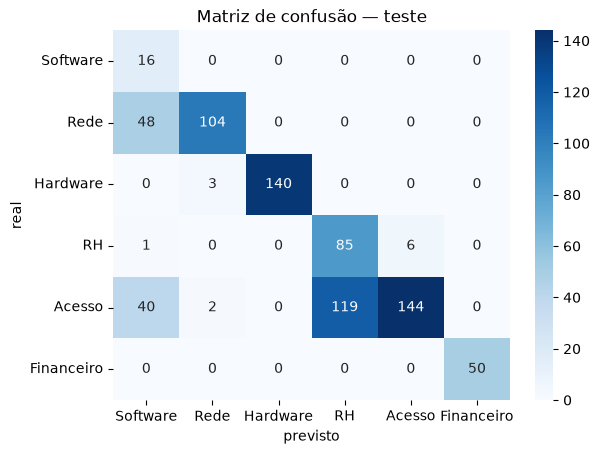

In [3]:
resumo = pd.DataFrame({p: {"acurácia": metricas[p]["accuracy"], "F1 macro": metricas[p]["f1_macro"]}
                       for p in ("train", "validation", "test")}).T
confusao = pd.read_csv(DIR / "test_confusion.csv", index_col=0, encoding="utf-8-sig")
display(resumo.round(3))
sns.heatmap(confusao, annot=True, fmt="d", cmap="Blues").set(title="Matriz de confusão — teste", xlabel="previsto", ylabel="real")
plt.show()

**Principais pontos:**

- **Treino quase perfeito (F1 0,99), validação boa (0,90), teste bem menor (0,71).** O modelo aprende, mas generaliza pior do que a validação sugere.
- **Hardware e Financeiro vão bem.** Os erros se concentram em **Acesso** (confundido com RH e Software) e em **Rede** (confundida com Software).

**Por que o teste cai:**

1. **Divisão distorcida.** A divisão agrupa os chamados por imagem, mas há só 26 imagens; validação e teste ficaram com **4 imagens cada**, e o teste tem ~40% de Acesso e só 16 chamados de Software. Validação e teste medem coisas diferentes.
2. **Validação usada duas vezes.** Ela escolhe a melhor época **e** a melhor configuração, o que deixa seu F1 otimista.
3. **Imagens novas são quase ignoradas.** O vocabulário das legendas vem das 18 imagens do treino; nas imagens do teste, a maioria das palavras é desconhecida. Na prática, o modelo depende do texto do chamado.

---
**Código:** `src/models/fusion.py` (features, TF-IDF e MLP) · `src/models/fusion_pipeline.py` (validação do YAML, busca e avaliação) · `src/models/fusion_predict.py` (prever chamados novos sem retreinar). Os resultados ficam em `reports/fusion/<execução>/` e o modelo em `models/fusion/<execução>/`.